# TSB (Teunter–Syntetos–Babai) Method for Intermittent Demand Forecasting

A from-scratch educational implementation using NumPy, Pandas, Matplotlib, and scikit-learn.

**Learning objectives:** understand TSB's two components, implement the update equations, generate intermittent demand, create fitted and future forecasts, evaluate a chronological holdout, and explore smoothing parameters.

TSB is designed for intermittent demand: many zero-demand periods with occasional non-zero demand. Its key difference from Croston and SBA is that it updates demand-occurrence probability **every period**, including zero-demand periods.

## 1. Method intuition and equations

TSB tracks two estimates:
- `p_hat`: probability that demand is non-zero in a period.
- `z_hat`: average demand size, conditional on demand occurring.

Let `I_t = 1` when `y_t > 0`, otherwise `I_t = 0`.

**Occurrence probability (updated every period):**
`p_hat_t = beta * I_t + (1 - beta) * p_hat_(t-1)`

**Demand size (updated only when demand is non-zero):**
When `y_t > 0`: `z_hat_t = alpha * y_t + (1 - alpha) * z_hat_(t-1)`.
When `y_t = 0`, retain the previous `z_hat`.

**Forecast:** `TSB Forecast = p_hat * z_hat`

`alpha` smooths non-zero demand size; `beta` smooths occurrence probability. With no new observations, the multi-step point forecast remains constant at the latest estimated rate.

## 2. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
np.random.seed(42)

## 3. Generate synthetic intermittent demand

The series has many zero-demand periods and occasional demand. Demand becomes less frequent in the second half to demonstrate how the TSB occurrence probability can adapt.

In [2]:
n_periods = 72
dates = pd.date_range("2020-01-01", periods=n_periods, freq="MS")
demand = []

for t in range(n_periods):
    occurrence_probability = 0.35 if t < 42 else 0.15
    if np.random.rand() < occurrence_probability:
        demand.append(np.random.randint(8, 31))
    else:
        demand.append(0)

data = pd.DataFrame({"Date": dates, "Demand": demand})
data.head(10)

,Date,Demand
0,2020-01-01,0
1,2020-02-01,0
2,2020-03-01,0
3,2020-04-01,0
4,2020-05-01,26
5,2020-06-01,18
6,2020-07-01,0
7,2020-08-01,0
8,2020-09-01,0
9,2020-10-01,9


## 4. Explore the demand pattern

Total periods: 72
Zero-demand periods: 54
Non-zero-demand periods: 18
Zero-demand percentage: 75.00%
Average non-zero demand: 21.67


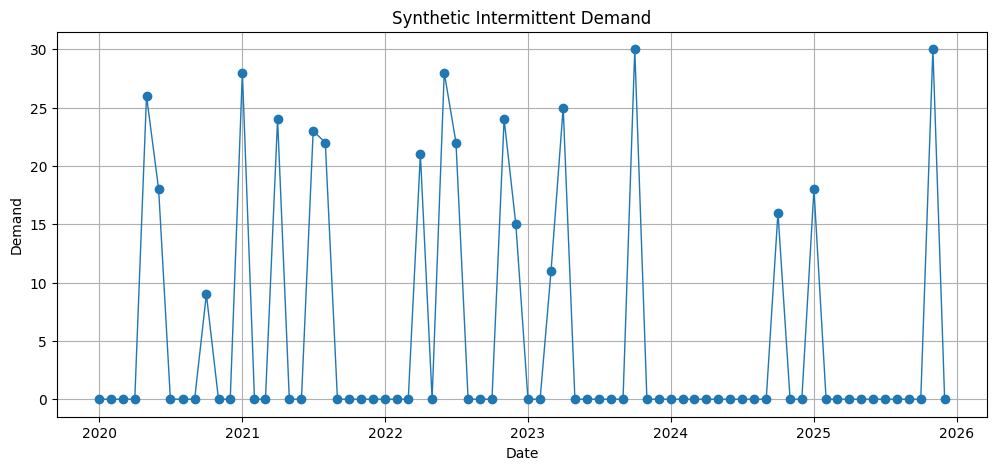

In [3]:
zero_count = (data.Demand == 0).sum()
nonzero_count = (data.Demand > 0).sum()

print(f"Total periods: {len(data)}")
print(f"Zero-demand periods: {zero_count}")
print(f"Non-zero-demand periods: {nonzero_count}")
print(f"Zero-demand percentage: {zero_count / len(data) * 100:.2f}%")
print(f"Average non-zero demand: {data.loc[data.Demand > 0, 'Demand'].mean():.2f}")

plt.figure()
plt.plot(data.Date, data.Demand, marker="o", linewidth=1)
plt.title("Synthetic Intermittent Demand")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.show()

## 5. Implement TSB from scratch

Initialization in this example:
- Initial demand-size estimate: first non-zero observation.
- Initial occurrence probability: first-period occurrence indicator; if the first period is zero, use the overall occurrence rate.

For each observation, the one-step-ahead forecast is recorded **before** updating the estimates with that period's actual demand. This avoids using the current observation to forecast itself.

In [4]:
def tsb_forecast(demand, alpha=0.2, beta=0.1,
                 initial_probability=None, initial_demand_size=None):
    """Return one-step-ahead fitted values, state histories, and final TSB state."""
    y = np.asarray(demand, dtype=float)

    if y.ndim != 1 or len(y) == 0:
        raise ValueError("demand must be a non-empty 1D sequence")
    if np.any(y < 0):
        raise ValueError("This implementation expects non-negative demand")
    if not (0 < alpha <= 1 and 0 < beta <= 1):
        raise ValueError("alpha and beta must be in (0, 1]")

    nonzero = y[y > 0]
    if len(nonzero) == 0:
        raise ValueError("At least one non-zero demand observation is required")

    if initial_probability is None:
        initial_probability = float(y[0] > 0) if y[0] > 0 else float(np.mean(y > 0))
    if initial_demand_size is None:
        initial_demand_size = float(nonzero[0])

    p_hat = float(initial_probability)
    z_hat = float(initial_demand_size)
    fitted, p_history, z_history = [], [], []

    for actual in y:
        # Forecast with estimates available before observing this period.
        fitted.append(p_hat * z_hat)

        occurrence = 1.0 if actual > 0 else 0.0

        # Probability is updated every period, including zero-demand periods.
        p_hat = beta * occurrence + (1 - beta) * p_hat

        # Demand size is updated only when demand is non-zero.
        if actual > 0:
            z_hat = alpha * actual + (1 - alpha) * z_hat

        p_history.append(p_hat)
        z_history.append(z_hat)

    return {
        "fitted": np.asarray(fitted),
        "probability": np.asarray(p_history),
        "demand_size": np.asarray(z_history),
        "final_probability": p_hat,
        "final_demand_size": z_hat,
        "final_forecast": p_hat * z_hat
    }

## 6. Fit TSB and visualize its components

In [5]:
ALPHA = 0.2  # Smoothing for non-zero demand size
BETA = 0.1    # Smoothing for occurrence probability

result = tsb_forecast(data.Demand, alpha=ALPHA, beta=BETA)
data["TSB_Fitted"] = result["fitted"]
data["Occurrence_Probability"] = result["probability"]
data["Smoothed_Demand_Size"] = result["demand_size"]

print(f"Final occurrence probability: {result['final_probability']:.4f}")
print(f"Final smoothed demand size: {result['final_demand_size']:.2f}")
print(f"Final TSB forecast: {result['final_forecast']:.2f} units per period")
data.tail()

Final occurrence probability: 0.1667
Final smoothed demand size: 22.46
Final TSB forecast: 3.74 units per period


,Date,Demand,TSB_Fitted,Occurrence_Probability,Smoothed_Demand_Size
67,2025-08-01,0,2.673500,0.116966,20.57140
68,2025-09-01,0,2.406150,0.105269,20.57140
69,2025-10-01,0,2.165535,0.094742,20.57140
70,2025-11-01,30,1.948981,0.185268,22.45712
71,2025-12-01,0,4.160587,0.166741,22.45712


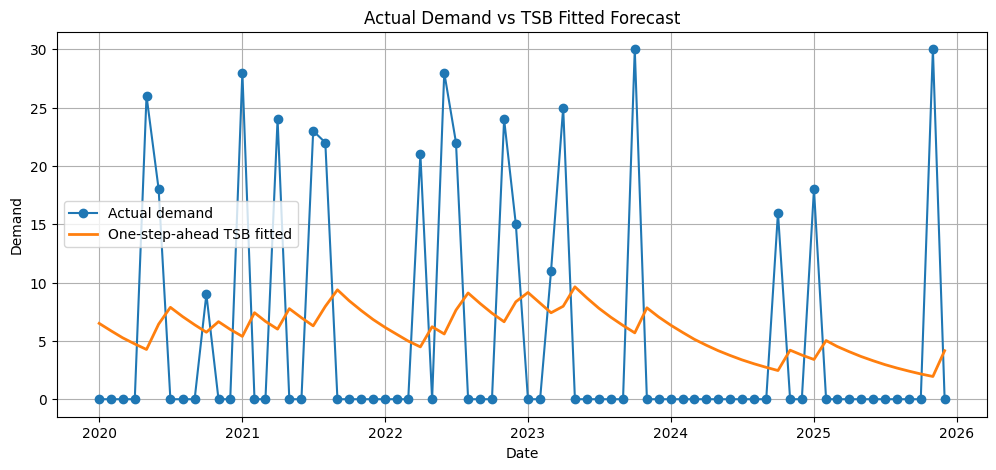

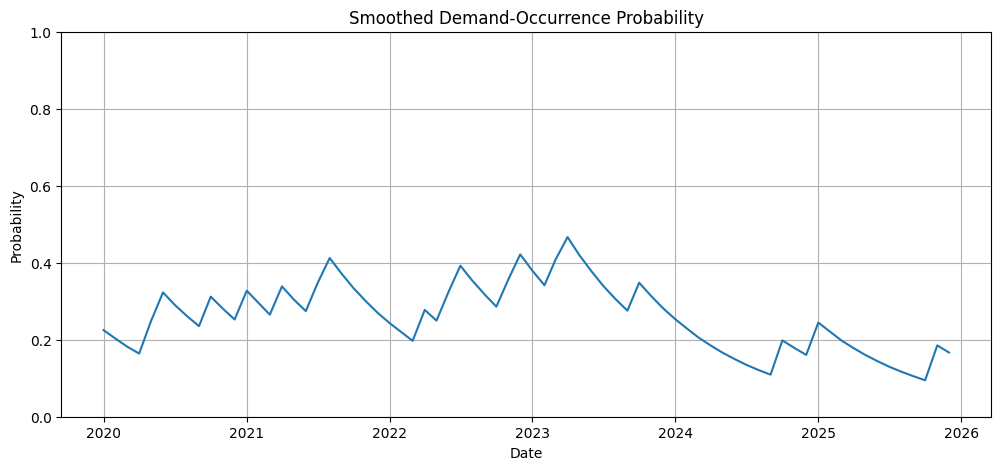

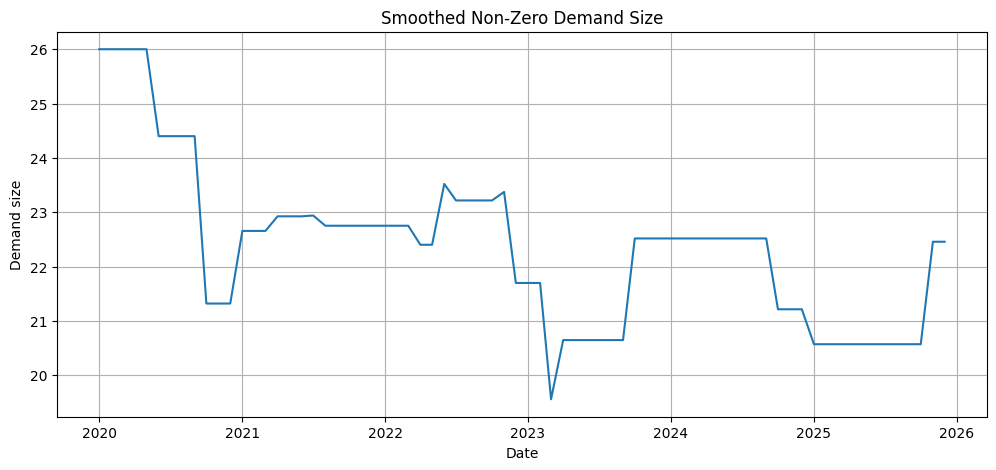

In [6]:
plt.figure()
plt.plot(data.Date, data.Demand, marker="o", label="Actual demand")
plt.plot(data.Date, data.TSB_Fitted, linewidth=2, label="One-step-ahead TSB fitted")
plt.title("Actual Demand vs TSB Fitted Forecast")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.show()

plt.figure()
plt.plot(data.Date, data.Occurrence_Probability)
plt.title("Smoothed Demand-Occurrence Probability")
plt.xlabel("Date")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.show()

plt.figure()
plt.plot(data.Date, data.Smoothed_Demand_Size)
plt.title("Smoothed Non-Zero Demand Size")
plt.xlabel("Date")
plt.ylabel("Demand size")
plt.show()

## 7. Step-by-step example

A zero observation updates occurrence probability downward (if the estimate is positive), but leaves the demand-size estimate unchanged. A non-zero observation updates both components.

In [7]:
small_series = [0, 12, 0, 0, 20, 0]
example = tsb_forecast(
    small_series, alpha=0.2, beta=0.1,
    initial_probability=0.5, initial_demand_size=12
)

example_table = pd.DataFrame({
    "Period": np.arange(1, len(small_series) + 1),
    "Actual": small_series,
    "One_Step_Ahead_Forecast": example["fitted"],
    "Updated_Occurrence_Probability": example["probability"],
    "Updated_Demand_Size": example["demand_size"]
})
example_table

,Period,Actual,One_Step_Ahead_Forecast,Updated_Occurrence_Probability,Updated_Demand_Size
0,1,0,6.000000,0.450000,12.0
1,2,12,5.400000,0.505000,12.0
2,3,0,6.060000,0.454500,12.0
3,4,0,5.454000,0.409050,12.0
4,5,20,4.908600,0.468145,13.6
5,6,0,6.366772,0.421331,13.6


## 8. Chronological train-test evaluation

We train on earlier observations and test on later observations. The final TSB state from training is used for the test horizon. Without new actual observations, the multi-step forecast is constant.

MAPE is omitted because it is undefined or misleading when actual demand contains zeros. We use MAE, RMSE, and WMAPE.

In [8]:
split = int(len(data) * 0.8)
train = data.iloc[:split].copy()
test = data.iloc[split:].copy()

train_result = tsb_forecast(train.Demand, alpha=ALPHA, beta=BETA)
test_forecast = np.repeat(train_result["final_forecast"], len(test))

evaluation = pd.DataFrame({
    "Date": test.Date.values,
    "Actual": test.Demand.values,
    "TSB_Forecast": test_forecast
})
evaluation

,Date,Actual,TSB_Forecast
0,2024-10-01,16,2.459685
1,2024-11-01,0,2.459685
2,2024-12-01,0,2.459685
3,2025-01-01,18,2.459685
4,2025-02-01,0,2.459685
5,2025-03-01,0,2.459685
6,2025-04-01,0,2.459685
7,2025-05-01,0,2.459685
8,2025-06-01,0,2.459685
9,2025-07-01,0,2.459685


In [9]:
def calculate_metrics(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    mae = mean_absolute_error(actual, forecast)
    rmse = np.sqrt(mean_squared_error(actual, forecast))
    denominator = np.sum(np.abs(actual))
    wmape = (np.sum(np.abs(actual - forecast)) / denominator * 100
             if denominator != 0 else np.nan)
    return {"MAE": mae, "RMSE": rmse, "WMAPE (%)": wmape}

pd.DataFrame(
    [calculate_metrics(test.Demand, test_forecast)],
    index=["TSB"]
)

,MAE,RMSE,WMAPE (%)
TSB,5.742478,9.150268,134.589322


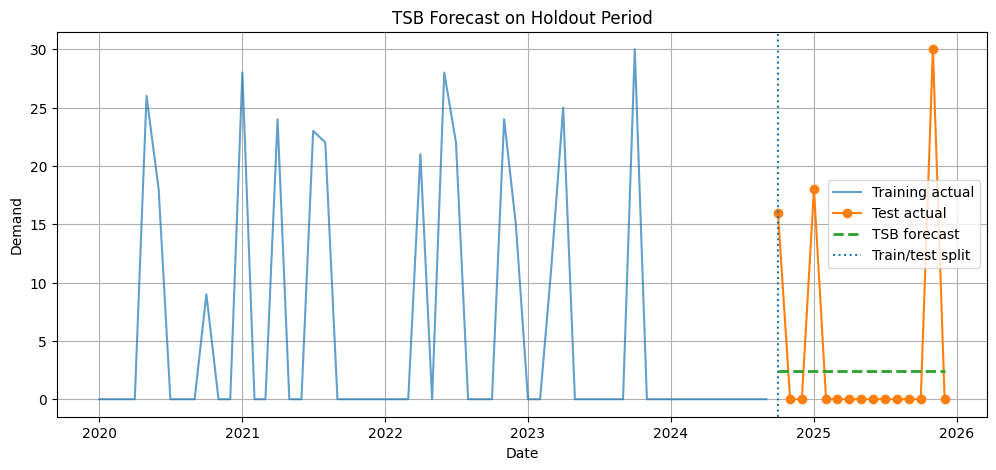

In [10]:
plt.figure()
plt.plot(train.Date, train.Demand, label="Training actual", alpha=0.7)
plt.plot(test.Date, test.Demand, marker="o", label="Test actual")
plt.plot(test.Date, test_forecast, linestyle="--", linewidth=2, label="TSB forecast")
plt.axvline(test.Date.iloc[0], linestyle=":", label="Train/test split")
plt.title("TSB Forecast on Holdout Period")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.show()

## 9. Experiment with alpha and beta

- Higher `beta`: occurrence probability reacts faster to recent zero/non-zero observations.
- Lower `beta`: occurrence probability changes more gradually.
- Higher `alpha`: demand-size estimate reacts faster to new non-zero demand sizes.
- Lower `alpha`: demand-size estimate is smoother.

This parameter grid is illustrative. In practice, tune parameters on a validation period or through rolling-origin backtesting, and keep the final test set untouched.

In [11]:
parameter_results = []

for alpha in [0.1, 0.2, 0.4]:
    for beta in [0.05, 0.1, 0.2, 0.4]:
        model = tsb_forecast(train.Demand, alpha=alpha, beta=beta)
        forecast = np.repeat(model["final_forecast"], len(test))
        parameter_results.append({
            "alpha": alpha,
            "beta": beta,
            **calculate_metrics(test.Demand, forecast)
        })

pd.DataFrame(parameter_results).sort_values("WMAPE (%)")

,alpha,beta,MAE,RMSE,WMAPE (%)
7,0.2,0.40,4.287943,9.917929,100.498672
3,0.1,0.40,4.288223,9.917730,100.505230
11,0.4,0.40,4.289290,9.916972,100.530232
6,0.2,0.20,4.673884,9.661043,109.544152
2,0.1,0.20,4.679239,9.657732,109.669673
10,0.4,0.20,4.699656,9.645173,110.148198
5,0.2,0.10,5.742478,9.150268,134.589322
1,0.1,0.10,5.761887,9.143935,135.044226
9,0.4,0.10,5.835881,9.120803,136.778469
4,0.2,0.05,6.848674,8.970149,160.515790


## 10. TSB vs Croston vs SBA

| Aspect | Croston | SBA | TSB |
|---|---|---|---|
| Demand-size estimate | Updated on non-zero demand | Same as Croston | Updated on non-zero demand |
| Frequency component | Inter-demand interval | Same as Croston | Occurrence probability updated every period |
| Bias correction | No | Yes | No SBA correction factor |
| Response to repeated zeros | Interval estimate updates at demand events | Same as Croston | Occurrence probability gradually declines |
| Key characteristic | Models intermittent demand | Bias-adjusted Croston estimate | Adapts when demand becomes less frequent |

TSB can be useful when demand may become obsolete or increasingly infrequent. It does not prove that an item is obsolete; it adjusts its forecast as evidence accumulates.

## 11. Advantages, limitations, and practical considerations

### Advantages
- Separately models demand occurrence and non-zero demand size.
- Updates occurrence probability every period, including zero-demand periods.
- Can reduce the forecast as demand becomes less frequent.
- Simple and computationally efficient.

### Limitations
- Without new observations, the multi-step forecast is constant.
- Results depend on initialization and smoothing parameters.
- Does not explicitly model trend, seasonality, or causal drivers.
- Cannot reliably distinguish temporary inactivity from permanent obsolescence by itself.

### Practical considerations
- Choose a time bucket that matches the replenishment decision (daily, weekly, monthly).
- Tune `alpha` and `beta` with validation or rolling-origin backtesting.
- Evaluate at item-location level where appropriate.
- Avoid MAPE when actual demand includes zeros.
- Compare against Croston, SBA, and simple baselines.
- Consider lead time, lifecycle, minimum order quantity, and obsolescence context.

## 12. Key takeaways

- TSB separates **how often demand occurs** from **how much is demanded when it occurs**.
- Occurrence probability is updated every period, even when demand is zero.
- Demand size is updated only when demand is non-zero.
- **TSB Forecast = Occurrence Probability × Smoothed Non-Zero Demand Size.**
- This makes TSB relevant for intermittent demand that may become less frequent over time.

## References
- Teunter, R. H., Syntetos, A. A., & Babai, M. Z. (2011). *Intermittent demand: Linking forecasting to inventory obsolescence*. European Journal of Operational Research.
- Forecasting: Principles and Practice: https://otexts.com/fpp3/